<a href="https://colab.research.google.com/github/Anshumanmalik/AI-in-Cyber-LAB-Assignment-3/blob/main/Lab_assignment_3_Anshuman_Malik_2401010086.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Q1. CNN, RNN/LSTM and GAN Concept Matching (5 marks)

| Model | Suitable data | Cyber-security example |
|---|---|---|
| CNN | Images or grid-like data | Malware image classification |
| RNN / LSTM | Sequences, logs and time-series events | Sequential intrusion or authentication-log analysis |
| GAN | Synthetic-data generation | Generate controlled synthetic attack samples |
| Dense network | Small numeric feature tables | Normal/Attack classification using the four numeric features in this lab |

**Why a dense network is used:** The dataset represents each activity as four numeric feature values rather than an image or a time-ordered sequence. A dense neural network is therefore suitable for learning relationships among these tabular features.


## Q2. Dataset Preparation, Split and Normalization (5 marks)

The target column is `label`, where **0 = Normal** and **1 = Attack**. The four input features are `failed_logins`, `login_hour`, `new_device` and `data_transfer_mb`. `record_id` is an identifier, so it is not used as a predictive feature.

The data is split into 75% training and 25% testing data using `random_state=42` and stratification. `StandardScaler` is fitted only on the training features and then applied to both training and testing features. This puts numeric features on comparable scales and avoids using test-set information when fitting the scaler.


In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

# Upload the supplied CSV file
uploaded = files.upload()
csv_name = next((name for name in uploaded if name.lower().endswith('.csv')), None)
if csv_name is None:
    raise FileNotFoundError("Please upload simple_cyber_activity.csv")

df = pd.read_csv(csv_name)
print("Dataset shape:", df.shape)
display(df.head())
print("\\nClass counts (0 = Normal, 1 = Attack):")
print(df["label"].value_counts().sort_index())


Saving simple_cyber_activity.csv to simple_cyber_activity.csv
Dataset shape: (100, 6)


,record_id,failed_logins,login_hour,new_device,data_transfer_mb,label
0,1,4,1,0,164.9,1
1,2,3,3,1,250.6,1
2,3,3,10,0,145.1,0
3,4,2,11,0,397.8,0
4,5,1,3,0,409.3,0


\nClass counts (0 = Normal, 1 = Attack):
label
0    75
1    25
Name: count, dtype: int64


In [2]:
# Select the four features and binary target
features = [
    "failed_logins",
    "login_hour",
    "new_device",
    "data_transfer_mb"
]
X = df[features].copy()
y = df["label"].astype(int).copy()

# 75% training and 25% testing, preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Fit scaler on training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("\\nTraining class counts:")
print(y_train.value_counts().sort_index())
print("\\nTesting class counts:")
print(y_test.value_counts().sort_index())
print("\\nTraining feature means after standardization (approximately 0):")
print(np.round(X_train_scaled.mean(axis=0), 3))


Training shape: (75, 4)
Testing shape: (25, 4)
\nTraining class counts:
label
0    56
1    19
Name: count, dtype: int64
\nTesting class counts:
label
0    19
1     6
Name: count, dtype: int64
\nTraining feature means after standardization (approximately 0):
[ 0.  0. -0. -0.]


## Q3. Build and Train the Neural Network (10 marks)

The network architecture is **4–8–4–1**:
- Input: four feature values.
- First hidden layer: 8 neurons with ReLU activation.
- Second hidden layer: 4 neurons with ReLU activation.
- Output: one neuron with sigmoid activation, producing an attack probability from 0 to 1.

The model uses the Adam optimizer, binary cross-entropy loss and accuracy as a metric. It is trained for 20 epochs with batch size 8 and 20% of the training data reserved for validation.

**Definitions:** One epoch is one complete pass through the training data. Batch size is the number of training examples processed before the model updates its weights.


In [3]:
# Build the required 4-8-4-1 dense neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Train for 20 epochs
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)

print(f"Final training accuracy: {history.history['accuracy'][-1] * 100:.2f}%")
print(f"Final validation accuracy: {history.history['val_accuracy'][-1] * 100:.2f}%")


Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.2167 - loss: 0.7131 - val_accuracy: 0.2667 - val_loss: 0.7112
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.2333 - loss: 0.7056 - val_accuracy: 0.4000 - val_loss: 0.7035
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4000 - loss: 0.6994 - val_accuracy: 0.5333 - val_loss: 0.6968
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5333 - loss: 0.6943 - val_accuracy: 0.5333 - val_loss: 0.6916
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6000 - loss: 0.6901 - val_accuracy: 0.8000 - val_loss: 0.6869
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6667 - loss: 0.6866 - val_accuracy: 0.8000 - val_loss: 0.6829
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7167 - loss: 0.6836 - val_accuracy: 0.8000 - val_loss: 0.6793
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7500 - loss: 0.6810 - val_accuracy: 0.8667 - val_loss: 0.6759


## Q4. Accuracy/Loss Curves and Test Evaluation (10 marks)

Accuracy is the proportion of correctly classified records. Loss measures prediction error according to the selected loss function. The two graphs below show training and validation performance across epochs. The held-out test set is evaluated separately.


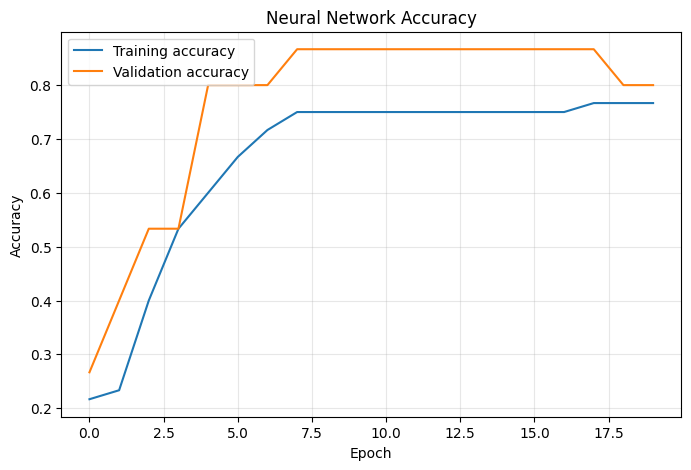

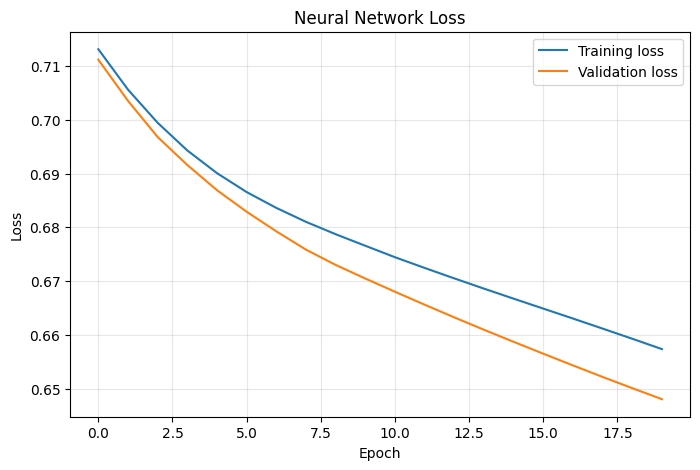

Test accuracy: 84.00%
Test loss: 0.6522


In [5]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Neural Network Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Neural Network Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Evaluate on the held-out test set
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")


In [6]:
# Generate a simple, data-based interpretation of the learning curves
train_acc = history.history["accuracy"][-1]
val_acc = history.history["val_accuracy"][-1]
train_loss = history.history["loss"][-1]
val_loss = history.history["val_loss"][-1]

gap = train_acc - val_acc
print("Learning-curve interpretation:")
if gap > 0.15 and val_loss > train_loss:
    print("Training performance is noticeably better than validation performance. This may indicate overfitting.")
elif train_acc < 0.65 and val_acc < 0.65:
    print("Both training and validation accuracy are relatively low. This may indicate underfitting or limited predictive information.")
else:
    print("Training and validation performance are reasonably close. There is no strong overfitting signal from the final accuracy values alone.")
print("Always inspect both plotted curves before writing your final interpretation.")


Learning-curve interpretation:
Training and validation performance are reasonably close. There is no strong overfitting signal from the final accuracy values alone.
Always inspect both plotted curves before writing your final interpretation.


## Q5. New Predictions and Decision Tree Comparison (10 marks)

Three new records are passed through the same fitted scaler and neural network. A probability of at least 0.50 is classified as **Attack**; otherwise it is **Normal**. A Decision Tree with `max_depth=4` is trained on the same training split and evaluated on the same test split.


In [7]:
# Three new cyber-activity records specified in the lab manual
new_records = pd.DataFrame([
    {"failed_logins": 0, "login_hour": 11, "new_device": 0, "data_transfer_mb": 35},
    {"failed_logins": 7, "login_hour": 1,  "new_device": 1, "data_transfer_mb": 250},
    {"failed_logins": 2, "login_hour": 23, "new_device": 1, "data_transfer_mb": 850}
], columns=features)

# Neural-network predictions
new_scaled = scaler.transform(new_records)
probabilities = model.predict(new_scaled, verbose=0).flatten()
new_results = new_records.copy()
new_results["nn_probability"] = np.round(probabilities, 3)
new_results["nn_prediction"] = np.where(probabilities >= 0.50, "Attack", "Normal")

# Decision Tree trained on the same training split
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)

new_results["tree_prediction"] = np.where(
    tree.predict(new_records) == 1, "Attack", "Normal"
)

print(f"Neural-network test accuracy: {test_accuracy * 100:.2f}%")
print(f"Decision-tree test accuracy: {tree_accuracy * 100:.2f}%")
display(new_results)


Neural-network test accuracy: 84.00%
Decision-tree test accuracy: 88.00%


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.467,Normal,Normal
1,7,1,1,250,0.499,Normal,Attack
2,2,23,1,850,0.491,Normal,Attack


In [8]:
# Compare model test performance
comparison = pd.DataFrame({
    "Model": ["Dense Neural Network", "Decision Tree"],
    "Test Accuracy (%)": [test_accuracy * 100, tree_accuracy * 100]
})
display(comparison)

print("Decision Tree classification report:")
print(classification_report(y_test, tree_pred, target_names=["Normal", "Attack"], zero_division=0))

print("Decision Tree confusion matrix:")
print(confusion_matrix(y_test, tree_pred))


,Model,Test Accuracy (%)
0,Dense Neural Network,83.999997
1,Decision Tree,88.000000


Decision Tree classification report:
              precision    recall  f1-score   support

      Normal       0.86      1.00      0.93        19
      Attack       1.00      0.50      0.67         6

    accuracy                           0.88        25
   macro avg       0.93      0.75      0.80        25
weighted avg       0.90      0.88      0.86        25

Decision Tree confusion matrix:
[[19  0]
 [ 3  3]]


## Results, Discussion and Conclusion

Complete this section after running the notebook, using the actual outputs displayed above.

**Q2 – Dataset evidence:** The supplied dataset contains 100 records. Record the class counts and the printed training/testing shapes.

**Q3 – Training:** Record the final training accuracy and validation accuracy printed after the 20th epoch. The model summary above is evidence of the required 4–8–4–1 architecture.

**Q4 – Learning curves:** Insert/retain both graphs. Falling training loss indicates the model is fitting the training data. If validation loss begins rising while training loss continues falling, or training accuracy becomes much higher than validation accuracy, this can indicate overfitting. If both accuracies remain low, this may indicate underfitting.

**Q5 – Prediction comparison:** Use the three-row prediction table and the two test accuracies. Agreement between the neural network and Decision Tree gives additional support to a prediction; disagreement should be reviewed rather than treated as certainty.

**Why choose a Decision Tree?** If its performance is similar to the neural network, it may be preferred because its decision rules are easier to interpret and explain.

**Conclusion:** This lab prepared and standardized the cyber-activity dataset, trained a dense neural network with the required 4–8–4–1 architecture, evaluated its accuracy and loss, predicted three new records, and compared its test performance with a Decision Tree. The actual measured results from the notebook should be used in the final lab record.


## Submission checklist

- [ ] Q1 concept-matching table and dense-network justification.
- [ ] Q2 class counts and training/testing shapes.
- [ ] Q3 model summary and training output.
- [ ] Q4 accuracy and loss graphs, test accuracy and test loss.
- [ ] Q5 three new predictions and model comparison.
- [ ] Written interpretation and conclusion.

**Important:** Run all cells in order and keep your actual Colab outputs. The lab manual's sample accuracies are illustrative, not guaranteed results for every run.
